### Show violin plots for numerical features against the target by manually calculating kernel density estimates and constructing the distribution using only low-level plotting functions without using Seaborn or built-in violin plot methods.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
print(df.columns)

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')


In [4]:
numeric_columns = df.select_dtypes(include="number").columns

print(numeric_columns)

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')


In [5]:
features = []

for column in numeric_columns:

    if column != "target":
        features.append(column)

print(features)

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [6]:
def manual_kde(values):

    values = np.array(values, dtype=float)

    minimum = np.min(values)
    maximum = np.max(values)

    x_values = np.linspace(
        minimum,
        maximum,
        100
    )

    n = len(values)

    mean = np.mean(values)
    std = np.std(values)

    if std == 0:
        std = 1

    bandwidth = 1.06 * std * (n ** (-1 / 5))

    if bandwidth == 0:
        bandwidth = 1

    density = []

    for x in x_values:

        total = 0

        for value in values:

            z = (x - value) / bandwidth

            kernel = np.exp(
                -0.5 * z * z
            )

            total = total + kernel

        result = total / (
            n * bandwidth * np.sqrt(2 * np.pi)
        )

        density.append(result)

    return x_values, np.array(density)

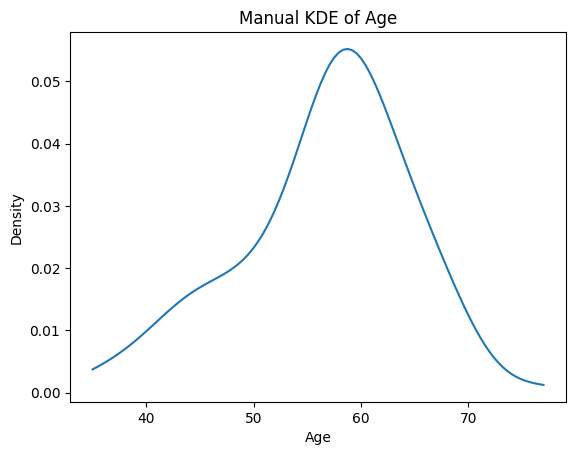

In [10]:
values = df[df["target"] == 0]["age"].dropna()

x_values, density = manual_kde(values)

plt.plot(
    x_values,
    density
)

plt.xlabel("Age")
plt.ylabel("Density")

plt.title("Manual KDE of Age")

plt.show()

In [11]:
def draw_violin(values, position):

    values = values.dropna()

    x_values, density = manual_kde(values)

    maximum_density = np.max(density)

    if maximum_density == 0:
        maximum_density = 1

    width = 0.4

    density = (density / maximum_density) * width

    left_side = position - density
    right_side = position + density

    plt.fill_betweenx(
        x_values,
        left_side,
        right_side,
        alpha=0.6
    )

    plt.plot(
        left_side,
        x_values
    )

    plt.plot(
        right_side,
        x_values
    )

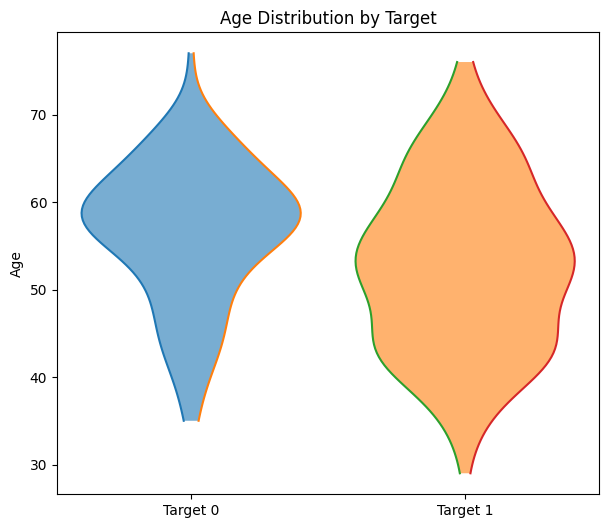

In [12]:
target_0_age = df[df["target"] == 0]["age"]

target_1_age = df[df["target"] == 1]["age"]

plt.figure(figsize=(7, 6))

draw_violin(
    target_0_age,
    1
)

draw_violin(
    target_1_age,
    2
)

plt.xticks(
    [1, 2],
    ["Target 0", "Target 1"]
)

plt.ylabel("Age")

plt.title("Age Distribution by Target")

plt.show()

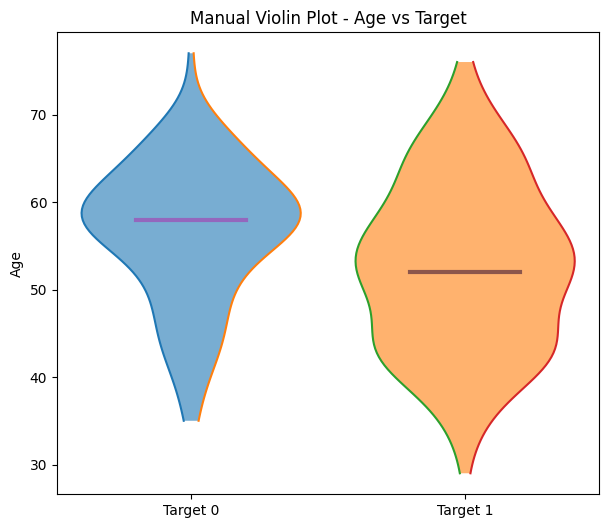

In [13]:
median_0 = np.median(
    target_0_age.dropna()
)

median_1 = np.median(
    target_1_age.dropna()
)

plt.figure(figsize=(7, 6))

draw_violin(
    target_0_age,
    1
)

draw_violin(
    target_1_age,
    2
)

plt.plot(
    [0.8, 1.2],
    [median_0, median_0],
    linewidth=3
)

plt.plot(
    [1.8, 2.2],
    [median_1, median_1],
    linewidth=3
)

plt.xticks(
    [1, 2],
    ["Target 0", "Target 1"]
)

plt.ylabel("Age")

plt.title("Manual Violin Plot - Age vs Target")

plt.show()

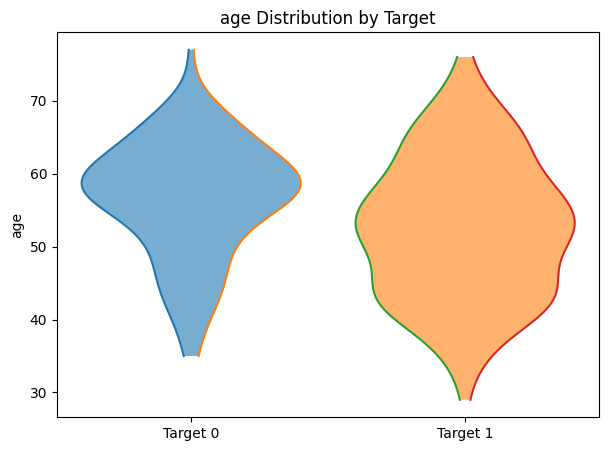

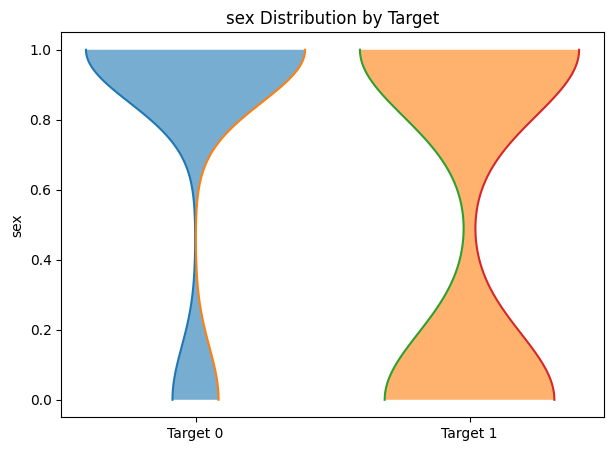

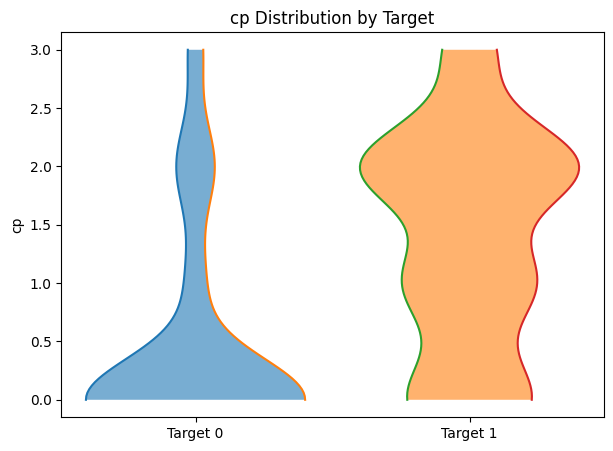

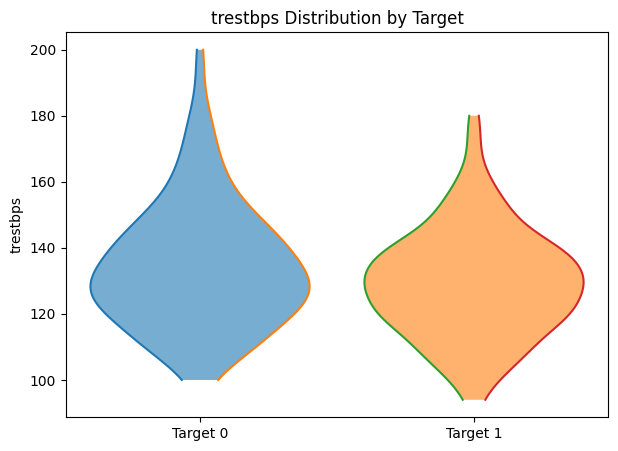

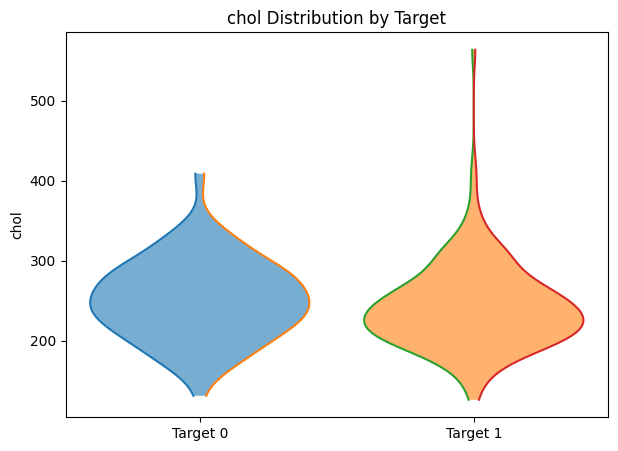

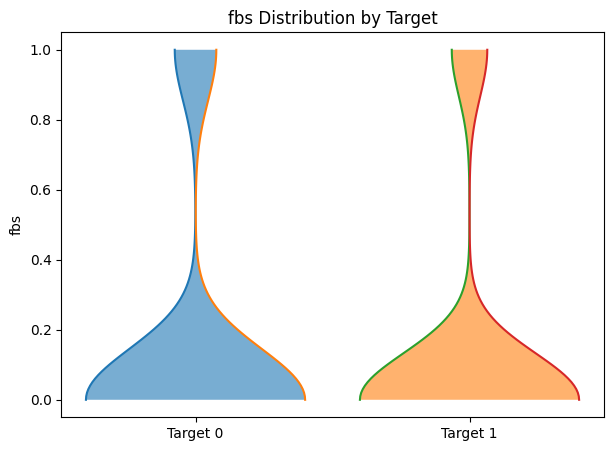

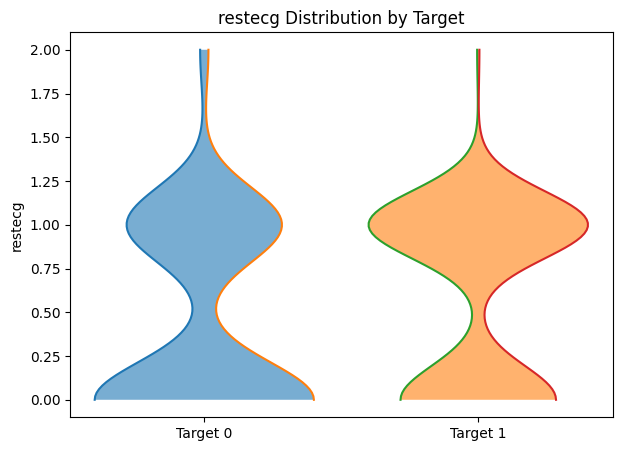

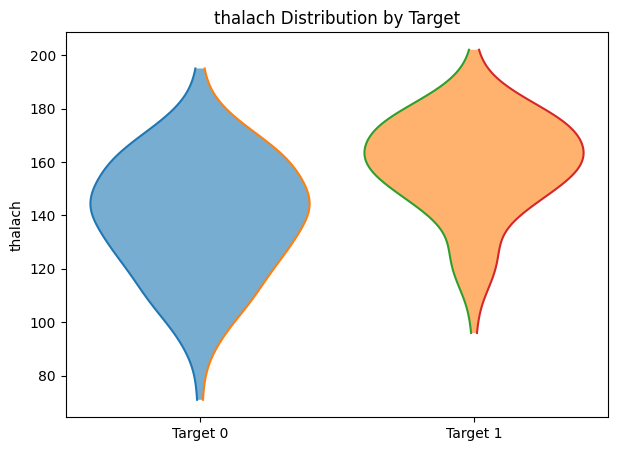

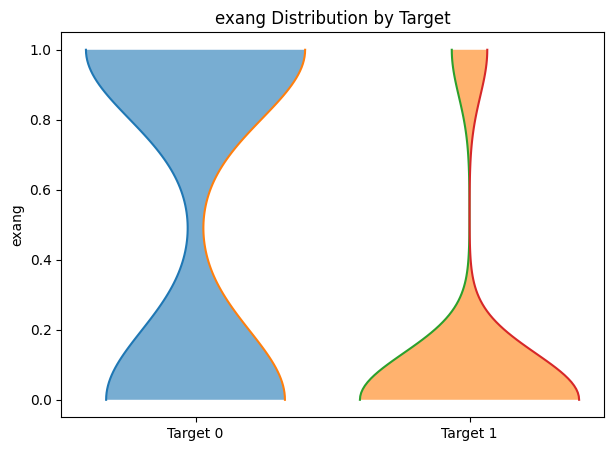

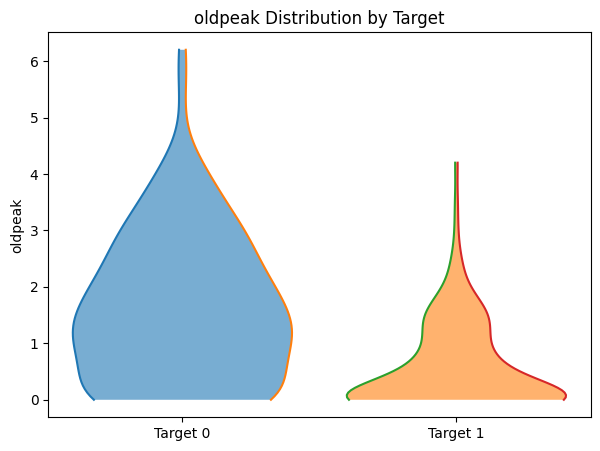

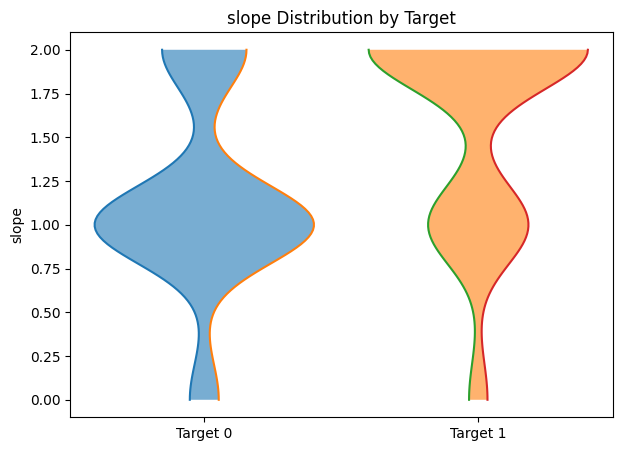

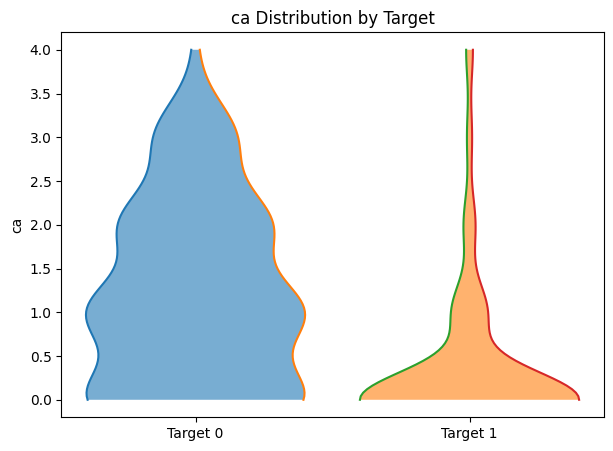

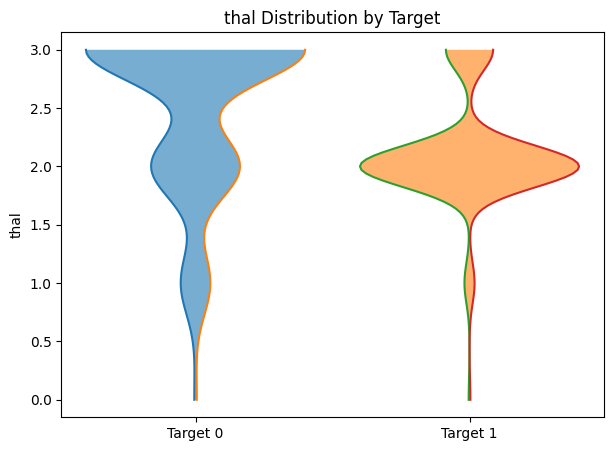

In [14]:
for feature in features:

    target_0 = df[
        df["target"] == 0
    ][feature].dropna()

    target_1 = df[
        df["target"] == 1
    ][feature].dropna()

    plt.figure(figsize=(7, 5))

    draw_violin(
        target_0,
        1
    )

    draw_violin(
        target_1,
        2
    )

    plt.xticks(
        [1, 2],
        ["Target 0", "Target 1"]
    )

    plt.ylabel(feature)

    plt.title(
        feature + " Distribution by Target"
    )

    plt.show()